# Starter Notebook | دفتر البداية
### Echoes of Recitation | صدى التلاوة

**EN:** Each clip is a short recitation containing one of four rules: **Izhar, Idgham, Iqlab, Ikhfa**. Your model must recognise the rule. The twist: the test clips are recited by **sheikhs who never appear in the training data**.

This notebook shows the full pipeline: load → listen → visualise → dummy baseline → `submission.csv`.

**AR:** كل مقطع تلاوة قصيرة تحتوي على حكم واحد من أربعة: **الإظهار، الإدغام، الإقلاب، الإخفاء**. المطلوب أن يتعرّف نموذجك على الحكم. التحدي: مقاطع الاختبار بأصوات **مشايخ لم يظهروا في بيانات التدريب إطلاقاً**.

يوضّح هذا الدفتر المسار الكامل: التحميل ← الاستماع ← التمثيل بالرسوم ← نموذج مبدئي ← ملف `submission.csv`.

## 1. Load the data | تحميل البيانات

In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, librosa.display
from IPython.display import Audio, display

hits = glob.glob('/kaggle/input/**/train.csv', recursive=True)
DATA = os.path.dirname(hits[0]) if hits else '.'
print('Data folder:', DATA)

train  = pd.read_csv(f'{DATA}/train.csv')             # id, label
test   = pd.read_csv(f'{DATA}/test.csv')              # id
sample = pd.read_csv(f'{DATA}/sample_submission.csv') # id, label
SR = 16000                                            # all clips: 16 kHz mono

def path(split, clip_id):
    return f'{DATA}/{split}/{clip_id}.wav'

print(train.shape, test.shape)
train.head()

Data folder: /kaggle/input/competitions/echoes-of-recitation/Dataset
(854, 2) (397, 1)


,id,label
0,tr_56eff6dea2,Ikhfa
1,tr_5da33f15c3,Iqlab
2,tr_44f354d8a6,Idgham
3,tr_3f31be1cb8,Izhar
4,tr_14a99eddfd,Iqlab


## 2. The four rules | الأحكام الأربعة
| Label | الحكم | What you hear / ماذا تسمع |
| --- | --- | --- |
| `Izhar` | الإظهار | The noon is pronounced clearly, no nasal merging / النون تُنطق واضحة بلا غنة |
| `Idgham` | الإدغام | The noon merges into the next letter / النون تُدغم في الحرف التالي |
| `Iqlab` | الإقلاب | The noon turns into a hidden meem before ب / النون تُقلب ميماً مخفاة قبل الباء |
| `Ikhfa` | الإخفاء | The noon is hidden with a nasal sound (ghunnah) / النون تُخفى مع الغنة |

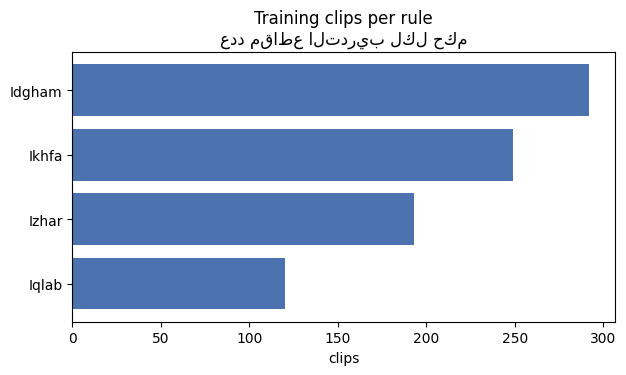

Note: Iqlab is the rarest rule. / ملاحظة: الإقلاب هو الأقل عدداً.


In [2]:
counts = train.label.value_counts().sort_values()
plt.figure(figsize=(7, 3.5))
plt.barh(counts.index, counts.values, color='#4C72B0')
plt.title("Training clips per rule\nعدد مقاطع التدريب لكل حكم"); plt.xlabel('clips'); plt.show()
print('Note: Iqlab is the rarest rule. / ملاحظة: الإقلاب هو الأقل عدداً.')

## 3. Listen | استمع

In [3]:
for label, g in train.groupby('label'):
    print(label)
    display(Audio(path('train', g.id.iloc[0])))

Idgham


Ikhfa


Iqlab


Izhar


## 4. Look at the sound | شاهد الصوت
**EN:** The mel spectrogram shows which frequencies are present over time. Nasal sounds (ghunnah) appear as steady low-frequency energy.

**AR:** الطيف الصوتي يُظهر الترددات مع الزمن. أصوات الغنة تظهر كطاقة ثابتة في الترددات المنخفضة.

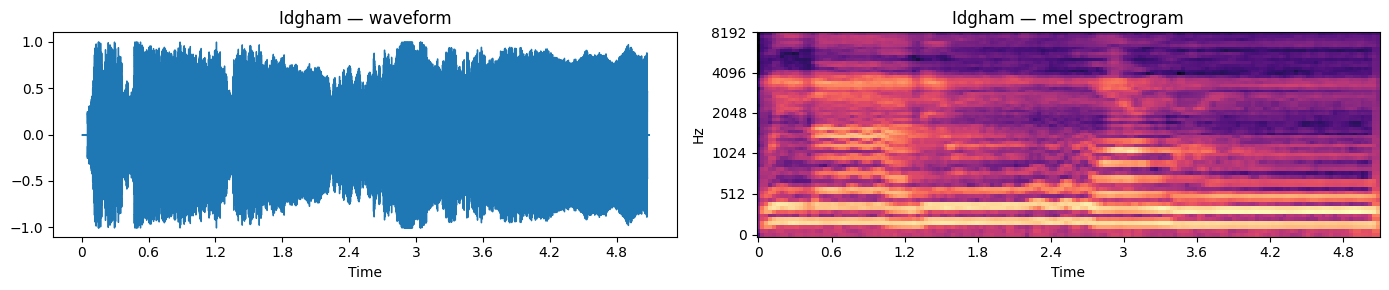

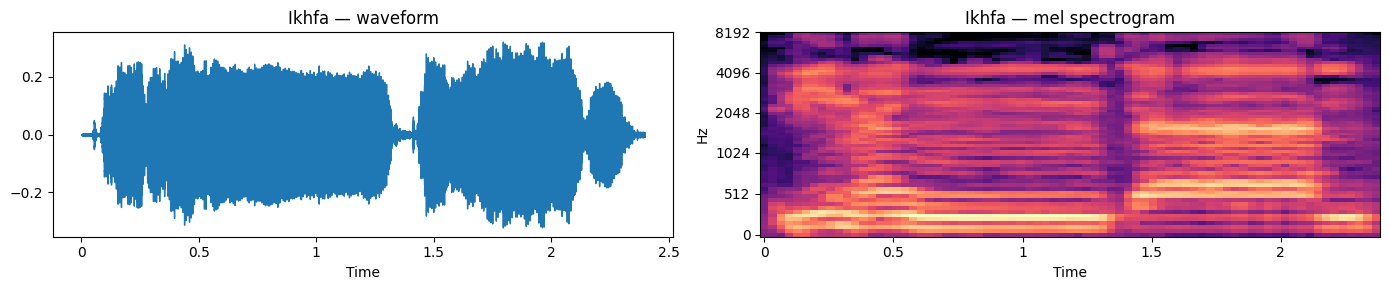

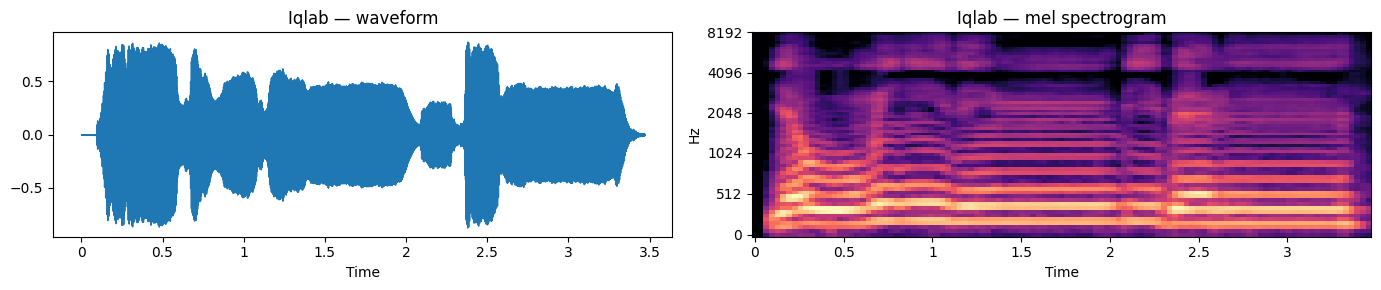

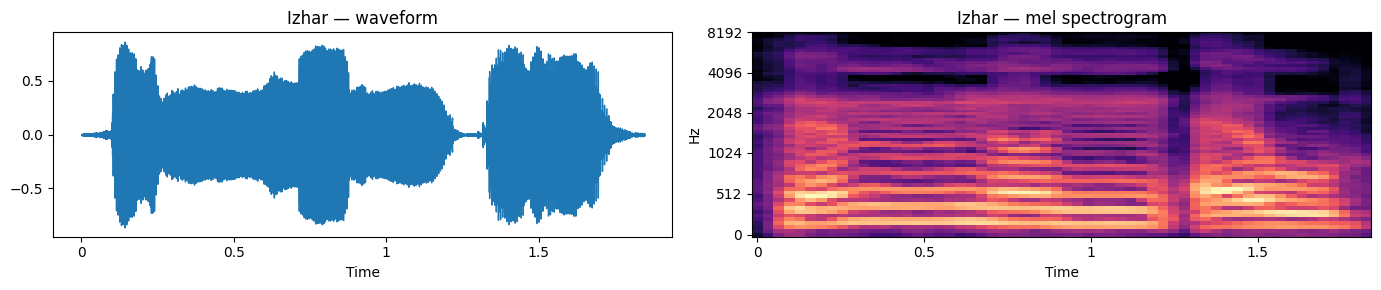

In [4]:
def show(split, clip_id, title):
    y, sr = librosa.load(path(split, clip_id), sr=SR)
    fig, ax = plt.subplots(1, 2, figsize=(14, 3))
    librosa.display.waveshow(y, sr=sr, ax=ax[0]); ax[0].set_title(f'{title} — waveform')
    S = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=sr, n_mels=64), ref=np.max)
    librosa.display.specshow(S, sr=sr, x_axis='time', y_axis='mel', ax=ax[1]); ax[1].set_title(f'{title} — mel spectrogram')
    plt.tight_layout(); plt.show()

for label in sorted(train.label.unique()):
    show('train', train[train.label == label].id.iloc[0], label)

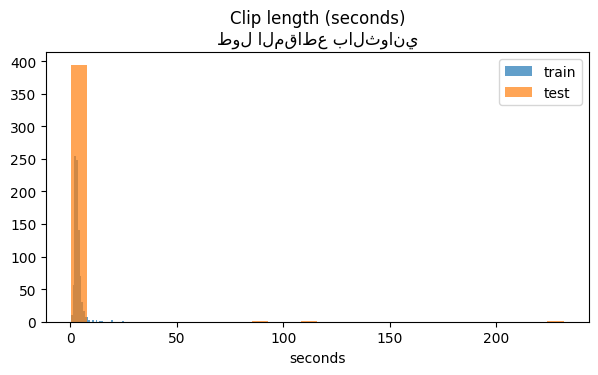

In [5]:
tr_d = [librosa.get_duration(path=path('train', i)) for i in train.id]
te_d = [librosa.get_duration(path=path('test', i)) for i in test.id]
plt.figure(figsize=(7, 3.5))
plt.hist(tr_d, bins=30, alpha=.7, label='train'); plt.hist(te_d, bins=30, alpha=.7, label='test')
plt.title('Clip length (seconds)\nطول المقاطع بالثواني'); plt.xlabel('seconds'); plt.legend(); plt.show()

## 5. A warning before you train | تنبيه قبل التدريب
**EN:** Your validation score may look excellent while your leaderboard score is close to random. Before trusting any number, explore the data carefully: listen, compare, count, and ask yourself what your model is *really* learning. The winners will be the ones who figure this out.

**AR:** قد تبدو نتيجة التحقق عندك ممتازة بينما نتيجتك في اللوحة قريبة من العشوائي. قبل أن تثق بأي رقم، استكشف البيانات جيداً: استمع، قارن، احسب، واسأل نفسك ماذا يتعلم نموذجك *فعلاً*؟ الفائزون هم من يكتشفون ذلك.

## 6. Dummy baseline | النموذج المبدئي
**EN:** This baseline does **not** listen to the audio: it predicts the most common rule for every clip. It only shows the pipeline. Replace `my_model` with your own.

**AR:** هذا النموذج **لا** يستمع للصوت: يتنبأ بأكثر حكم تكراراً لكل المقاطع. هدفه توضيح المسار فقط. استبدل الدالة `my_model` بنموذجك.

In [6]:
from sklearn.metrics import f1_score

MOST_COMMON = train.label.value_counts().index[0]

def my_model(clip_path):
    # TODO: load audio, extract features, predict / حمّل الصوت واستخرج الخصائص وتنبّأ
    return MOST_COMMON

train_pred = [my_model(path('train', i)) for i in train.id]
print('Macro F1 on train / على التدريب:', round(f1_score(train.label, train_pred, average='macro'), 3))

Macro F1 on train / على التدريب: 0.127


In [7]:
def load_clip(split, cid, max_sec=12):
    x, _ = librosa.load(path(split, cid), sr=SR, mono=True)
    x, _ = librosa.effects.trim(x, top_db=35)      # قص الصمت من الأطراف
    if len(x) < SR // 4:                           # لو المقطع قصير جداً نحشيه
        x = np.pad(x, (0, SR // 4 - len(x)))
    x = x[: max_sec * SR]                          # أقصى طول 12 ثانية
    return (x / (np.abs(x).max() + 1e-8)).astype(np.float32)   # تطبيع مستوى الصوت

tr_audio = [load_clip('train', i) for i in train.id]
te_audio = [load_clip('test',  i) for i in test.id]
print('loaded', len(tr_audio), len(te_audio))

loaded 854 397


In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

def hand_feats(x):
    m = librosa.feature.mfcc(y=x, sr=SR, n_mfcc=20)
    return np.concatenate([m.mean(1), m.std(1)])

H_tr = np.array([hand_feats(x) for x in tr_audio])
H_te = np.array([hand_feats(x) for x in te_audio])

sc = StandardScaler().fit(np.vstack([H_tr, H_te]))
groups = KMeans(8, n_init=20, random_state=0).fit_predict(sc.transform(H_tr))
print('group sizes:', np.bincount(groups))

group sizes: [332 123 149  71  26  40  34  79]


In [9]:
import torch
from transformers import WhisperFeatureExtractor, WhisperModel

WHISPER = 'openai/whisper-small'
LAYERS  = [4, 6, 8, 10, 12]
dev   = 'cuda' if torch.cuda.is_available() else 'cpu'
dtype = torch.float16 if dev == 'cuda' else torch.float32
print('device:', dev)

FEATS_TR, FEATS_TE = {}, {}
try:
    fe  = WhisperFeatureExtractor.from_pretrained(WHISPER)
    enc = WhisperModel.from_pretrained(WHISPER).encoder.to(dev).to(dtype).eval()

    @torch.no_grad()
    def embed(audios, bs=16):
        out = {l: [] for l in LAYERS}
        for s in range(0, len(audios), bs):
            batch = audios[s:s + bs]
            inp = fe(batch, sampling_rate=SR, return_tensors='pt').input_features.to(dev).to(dtype)
            hs = enc(inp, output_hidden_states=True).hidden_states
            for l in LAYERS:
                for b, a in enumerate(batch):
                    n = max(2, int(len(a) / SR * 50))
                    h = hs[l][b, :n].float()
                    out[l].append(torch.cat([h.mean(0), h.std(0)]).cpu().numpy())
        return {l: np.array(v) for l, v in out.items()}

    FEATS_TR = {f'whisper_L{l}': v for l, v in embed(tr_audio).items()}
    FEATS_TE = {f'whisper_L{l}': v for l, v in embed(te_audio).items()}
    print('Whisper OK:', list(FEATS_TR))
except Exception as e:
    print('Whisper failed, using MFCC only:', repr(e)[:300])

FEATS_TR['mfcc'] = H_tr
FEATS_TE['mfcc'] = H_te
print('feature sets:', list(FEATS_TR))

device: cuda


preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  967MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

Whisper OK: ['whisper_L4', 'whisper_L6', 'whisper_L8', 'whisper_L10', 'whisper_L12']
feature sets: ['whisper_L4', 'whisper_L6', 'whisper_L8', 'whisper_L10', 'whisper_L12', 'mfcc']


In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold

LABELS = ['Idgham', 'Ikhfa', 'Iqlab', 'Izhar']
y = train.label.map({l: i for i, l in enumerate(LABELS)}).values

def make_model(C=0.05):
    return make_pipeline(StandardScaler(),
                         LogisticRegression(C=C, class_weight='balanced', max_iter=3000))

gkf = GroupKFold(5)
oof = {}
for name, X in FEATS_TR.items():
    P = np.zeros((len(y), 4))
    for tri, vai in gkf.split(X, y, groups):
        P[vai] = make_model().fit(X[tri], y[tri]).predict_proba(X[vai])
    oof[name] = P
    print(f'{name:12s} group-CV macro-F1 = {f1_score(y, P.argmax(1), average="macro"):.3f}')

best = sorted(oof, key=lambda k: -f1_score(y, oof[k].argmax(1), average='macro'))[:3]
ens = np.mean([oof[k] for k in best], axis=0)
print('\nTop-3:', best)
print('Ensemble group-CV macro-F1 =', round(f1_score(y, ens.argmax(1), average='macro'), 3))

whisper_L4   group-CV macro-F1 = 0.555
whisper_L6   group-CV macro-F1 = 0.600
whisper_L8   group-CV macro-F1 = 0.609
whisper_L10  group-CV macro-F1 = 0.617
whisper_L12  group-CV macro-F1 = 0.619
mfcc         group-CV macro-F1 = 0.331

Top-3: ['whisper_L12', 'whisper_L10', 'whisper_L8']
Ensemble group-CV macro-F1 = 0.62


In [11]:
P_te = np.mean([make_model().fit(FEATS_TR[k], y).predict_proba(FEATS_TE[k]) for k in best], axis=0)
pred_te = [LABELS[i] for i in P_te.argmax(1)]
print(pd.Series(pred_te).value_counts())

Idgham    278
Izhar      60
Ikhfa      53
Iqlab       6
Name: count, dtype: int64


In [12]:
prior = np.bincount(y, minlength=4) / len(y)     # توزيع الأحكام في التدريب (ترتيب LABELS)

def match_prior(P, prior, iters=500, lr=0.5):
    b = np.zeros(4)
    for _ in range(iters):
        Q = P * np.exp(b)
        Q /= Q.sum(1, keepdims=True)
        b += lr * (np.log(prior) - np.log(Q.mean(0)))
    return Q

P_adj = match_prior(P_te, prior)
pred_adj = [LABELS[i] for i in P_adj.argmax(1)]
print(pd.Series(pred_adj).value_counts())

Idgham    135
Ikhfa     123
Izhar      90
Iqlab      49
Name: count, dtype: int64


## 7. Create and save the submission | إنشاء ملف التسليم وحفظه

In [13]:
sub_adj = pd.DataFrame({'id': test.id, 'label': pred_adj})

assert list(sub_adj.columns) == ['id', 'label']
assert set(sub_adj.id) == set(sample.id)
assert sub_adj.label.isin(LABELS).all()

sub_adj.to_csv('submission_adj.csv', index=False)
print('Saved submission_adj.csv', sub_adj.shape)

Saved submission_adj.csv (397, 2)


In [14]:
submission = pd.DataFrame({'id': test.id, 'label': pred_te})
assert list(submission.columns) == ['id', 'label']
assert set(submission.id) == set(sample.id), 'every test clip needs a row'
assert submission.label.isin(['Izhar', 'Idgham', 'Iqlab', 'Ikhfa']).all(), 'unknown label'

submission.to_csv('submission.csv', index=False)
print('Saved submission.csv / تم الحفظ', submission.shape)
submission.head()

Saved submission.csv / تم الحفظ (397, 2)


,id,label
0,te_04f5ed4e5e,Izhar
1,te_81f13aa232,Idgham
2,te_ec5a8804cc,Idgham
3,te_fa862fc3c2,Ikhfa
4,te_ddf067f7fe,Izhar
